# Strong-lensing cosmography of a galaxy cluster with HMC and `glafic_jax`

This notebook models one cluster from `example_data/` and constrains flat
**w0waCDM** (Ω_m, w0, wa) jointly with the lens mass model, using
Hamiltonian Monte Carlo (NUTS) with exact JAX gradients.

**Choosing a cluster.** Set `CLUSTER` in the next cell to any folder name in
`example_data/`, or set the environment variable `GLAFIC_CLUSTER`. Each folder
holds catalogues in the glafic public-model format:

| file | columns |
|---|---|
| `glafic_<name>_vN_mulimage.txt` | ID (`system.image`), RA, Dec, positional error ["], z_s, z_s error (> 0: photometric, sampled) |
| `glafic_<name>_vN_memgal.txt` | RA, Dec, L/L*, e, PA of the cluster members (the brightest is the BCG) |
| `glafic_<name>_vN_readme.txt` | lens redshift (`# zl = ...`) and, optionally, the published fit (`# chi2 = .. , dof = ..`) |

To add a cluster, drop a new folder in `example_data/`. `build_cluster.py`
lists what it finds (`python build_cluster.py`).

**Mass model.** The glafic recipe of Oguri et al. (VENUS, 2026, Sec. 2.3):

* an elliptical NFW halo, with all 6 parameters free;
* pseudo-Jaffe members with σ ∝ L^1/4 and r_trun ∝ L^η, where σ*, r_trun* and
  η are free;
* external shear (`shear`, on by default);
* optional multipoles centred on the BCG (`mpoles`) and an optional separate
  BCG (`bcg`).

These are set per cluster in `CLUSTER_MODEL`, together with optional
**image parities** (`parity`, the sign of 1/μ). The source-plane χ² does not
check which side of a critical curve an image lies on. For an image pair
merging across a critical curve, this lets the posterior split into a
physical mode, with the curve between the two images, and an unphysical one.
Fixing their parities (opposite signs) removes the wrong mode; section 7
lists the close pairs and suggests the signs. Drop the shear when it is
consistent with zero: its angle is then unconstrained, and the amplitude–angle
pair forms a funnel at γ = 0 that NUTS samples poorly.

For RXJ2129, the base recipe reproduces the published fit but fails to form
the image pair 3.2/3.3, and an m = 3 multipole fixes that. For a new cluster,
start from the base recipe and let the image check in stage A tell you
whether anything is missing.

### Likelihood

We use glafic's **source-plane χ²** (`chi2_splane 1`), the choice of most
published cluster models:

* Each image's offset is mapped back to the source plane with the
  magnification tensor of the lens model.
* The source positions are **integrated out analytically**:
  χ² → χ²_min + ln det M, which removes two nuisance parameters per system.
* Positional errors are **rescaled** so that the ΛCDM best fit has
  χ²/dof = 1.

The μ² weighting in this χ² is what stops a model from placing images on
critical curves, where any image offset maps to a tiny source-plane residual.
Images that really do lie close to critical curves make the likelihood
sharply peaked, so NUTS needs long warmup and a high target acceptance. Do
**not** use `mag_cap`: capping the magnification removes that protection.

### Stages

Each stage caches its result in `results/<cluster>/<model tag>/`, and
re-running skips finished stages. Every cluster gets its own folder, and
changing the multipoles, the BCG or the halo-mass parameterization changes the
model tag, so stale chains are never reused. Each cached file also records its
cluster and model tag, and loading one into a different run raises an error.

| stage | what | cost (laptop CPU) |
|---|---|---|
| A | ΛCDM MAP; error calibration; image check with glafic's exact image finder | ~5 min |
| B | ΛCDM NUTS | hours |
| C | ΛCDM AIES (gradient-free) to validate NUTS | ~30 min |
| D | w0waCDM NUTS | hours |
| E | cosmology results and posterior-predictive check | minutes |

The `RUN_*` flags in the next cell run only some stages, for example one per
batch job; `RUN_A` alone checks the MAP in a few minutes. The samplers write
a checkpoint every `chunk` samples, so a job that hits its time limit resumes
where it stopped.

In [1]:
import os, sys, re, json, time, math
import numpy as np
import matplotlib.pyplot as plt

HERE = os.path.abspath(".")
REPO = os.path.abspath(os.path.join(HERE, "..", ".."))
try:
    import glafic_jax as gj
except ImportError:                      # not pip-installed: use the repository copy
    sys.path.insert(0, os.path.join(REPO, "python"))
    import glafic_jax as gj
import jax, jax.numpy as jnp
import build_cluster as build

print("jax", jax.__version__, "| backend:", jax.default_backend(), "| devices:", jax.devices())
print("clusters in example_data/:", build.available())

# ---------------- configuration ----------------
CLUSTER = os.environ.get("GLAFIC_CLUSTER", "mj0429")   # folder name in example_data/  rj2129
CLUSTER_MODEL = {                 # per-cluster additions to the base recipe
    "rj2129": dict(mpoles=[(3, 2)]),       # m = 3 needed to form images 3.2/3.3
    "mj0429": dict(shear=False,            # γ_ext = 0.012 ± 0.012: free shear only adds an unconstrained angle
                   parity={"3.3": -1, "3.4": +1}),   # merging pair: curve between them (section 7)
}
MPOLES = CLUSTER_MODEL.get(CLUSTER, {}).get("mpoles", [])   # (m, n) multipoles centred on the BCG
BCG = CLUSTER_MODEL.get(CLUSTER, {}).get("bcg", False)      # model the BCG separately
SHEAR = CLUSTER_MODEL.get(CLUSTER, {}).get("shear", True)   # external shear (amplitude, angle)
PARITY = CLUSTER_MODEL.get(CLUSTER, {}).get("parity", {})   # {image ID: ±1} required sign of 1/μ
MAG_CAP = 0.0                     # 0 = glafic's exact source-plane chi2 (do not cap; see above)
POS_ERR0 = 0.4                    # catalogue positional error [arcsec], before rescaling
CALIBRATE_ERRORS = True           # rescale errors so that the LCDM best fit has chi2/dof = 1
N_STARTS = 16                     # jittered L-BFGS starts for the MAP
USE_NFW_ALPHA = True              # halo mass: sample log10 of the NFW deflection at R (straightens M-c)
NFW_ALPHA_R = None                # [arcsec]; None = median image distance from the BCG
NFW_ALPHA_ZS = None               # source z for the deflection; None = median z_s
COSMO_REPARAM = {"wa": ("offset", "weos", -3.0, 0.0)}   # sample w0 + wa in [-3, 0)
NUTS_KW = dict(num_chains=4, num_warmup=1000, num_samples=1000, target_accept=0.95,
               max_tree_depth=10, init="map", init_jitter=0.01, use_approx_mass=False, chunk=250)
AIES_KW = dict(num_warmup=5000, num_samples=5000, thinning=5, init_jitter=0.005, chunk=1000)
RUN_A, RUN_B, RUN_C, RUN_D = True, True, True, True
SMOKE_TEST = False                # tiny runs, to check that the notebook works end to end

RESULTS = os.path.join(HERE, "results_smoke" if SMOKE_TEST else "results", CLUSTER)
if SMOKE_TEST:
    NUTS_KW.update(num_chains=2, num_warmup=20, num_samples=20, chunk=10, max_tree_depth=5)
    AIES_KW.update(num_warmup=100, num_samples=100, thinning=1, chunk=50)

jax 0.12.0.1 | backend: gpu | devices: [CudaDevice(id=0)]
clusters in example_data/: ['mj0429', 'rj2129']


## 1. Data

mj0429: z_l = 0.399; 21 images of 6 systems, 1.40 < z_s < 3.87 (3 photometric); 136 members; images at 2.6-27.7" from the BCG; published fit chi2 = 13.39 for 24 dof
model: base_noshear_nfwa14.5z2.36  ->  /global/cfs/cdirs/deepsrch/lensed_sne_search/glafic2/examples_jax/cluster_cosmo/results/mj0429/base_noshear_nfwa14.5z2.36
# glafic input for mj0429 (generated by build_cluster.py)
omega     0.300000
lambda    0.700000
weos     -1.000000
hubble    0.700000
prefix    mj0429
xmin     -60.0
ymin     -60.0
xmax      60.0
ymax      60.0
pix_ext   0.2
pix_poi   1.0
maxlev    6
galfile   mj0429_galfile.dat
chi2_splane    1
chi2_checknimg 0
flatfix   1
ovary     1
wvary     1
wavary    1
hvary     0

startup 2 0 6
lens anfw  0.399 8.0e14  0.0  0.0  0.4  -20.0  6.0  0.0
lens gals  0.399 200.0   0.0  0.0  0.0    0.0 20.0  1.0
point 2.9290 0.5540 0.8657
point 3.8670 5.2650 -3.3809
point 3.8670 -0.8178 0.9725
point 1.8000 -0.7280 -4.2535
point 1.7000 -1.3762 -9.3930
point 1.4000 1.6533 8.5230
end_s

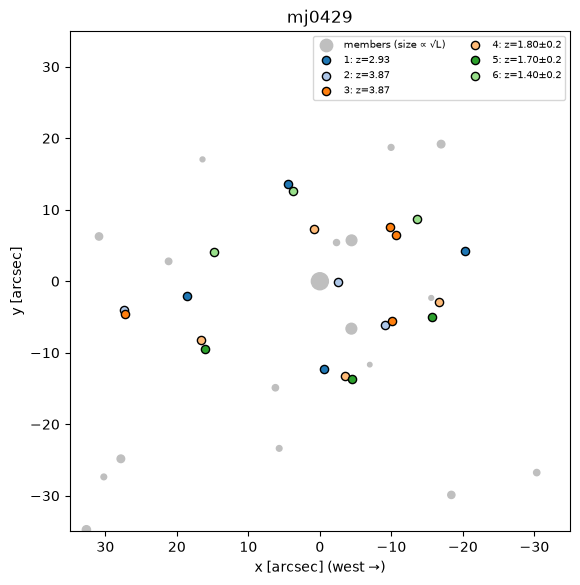

In [2]:
cl = build.load(CLUSTER)
print(build.summary(cl))
systems = cl["systems"]
SIDS = list(systems)                                   # catalogue system IDs, in glafic point order
xy_all = np.concatenate([np.array(s["xy"]) for s in systems.values()])
r_img = np.hypot(*xy_all.T)
zs_all = np.array([s["zs"] for s in systems.values()])
LIM = 5.0 * math.ceil(1.25 * r_img.max() / 5.0)        # plot half-width [arcsec]

# halo-mass parameterization (data-driven defaults)
if NFW_ALPHA_R is None:
    NFW_ALPHA_R = float(np.round(2 * np.median(r_img)) / 2)
if NFW_ALPHA_ZS is None:
    NFW_ALPHA_ZS = float(np.round(np.median(zs_all), 2))
REPARAM = {"lens1_anfw_p2": ("nfw_alpha", NFW_ALPHA_R, NFW_ALPHA_ZS) if USE_NFW_ALPHA else "log10",
           "lens2_gals_p7": "log10"}          # member truncation radius: flat in log10

# results folder for this model setup
TAG = "_".join(["base"] + ([] if SHEAR else ["noshear"]) + [f"mpole{m}{n}" for m, n in MPOLES]
               + (["bcg"] if BCG else [])
               + (["par" + "-".join(sorted(PARITY))] if PARITY else [])
               + [f"nfwa{NFW_ALPHA_R:g}z{NFW_ALPHA_ZS:g}" if USE_NFW_ALPHA else "log10M"])
RUN_DIR = os.path.join(RESULTS, TAG)
os.makedirs(RUN_DIR, exist_ok=True)
print(f"model: {TAG}  ->  {RUN_DIR}")


def write_files(outdir, pos_err):
    return build.write_all(CLUSTER, outdir, mpoles=MPOLES, bcg=BCG, shear=SHEAR, parity=PARITY,
                           pos_err=pos_err)


write_files(RUN_DIR, POS_ERR0)
print(open(os.path.join(RUN_DIR, f"{CLUSTER}.input")).read().split("start_command")[0])

gals = cl["gals"][1:] if BCG else cl["gals"]
cmap = plt.get_cmap("tab20")
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(gals[:, 0], gals[:, 1], s=150 * gals[:, 2] ** 0.5, c="0.75", label="members (size ∝ √L)")
for k, (sid, s) in enumerate(systems.items()):
    xy = np.array(s["xy"])
    ax.scatter(xy[:, 0], xy[:, 1], s=35, color=cmap(k % 20), edgecolor="k", zorder=3,
               label=f"{sid}: z={s['zs']:.2f}" + (f"±{s['zerr']:.1f}" if s['zerr'] > 0 else ""))
ax.set_xlim(LIM, -LIM); ax.set_ylim(-LIM, LIM); ax.set_aspect("equal")
ax.set_xlabel("x [arcsec] (west →)"); ax.set_ylabel("y [arcsec]"); ax.legend(fontsize=7, ncol=2)
ax.set_title(CLUSTER)
plt.show()

In [3]:
def capdir(cap):
    d = os.path.join(RUN_DIR, f"cap{cap:g}")
    os.makedirs(d, exist_ok=True)
    return d


def make_model(cap, cosmology_free=False, lens=None, poi=None):
    m = gj.read_input(os.path.join(capdir(cap), f"{CLUSTER}.input"))
    for k in ("ovary", "wvary", "wavary"):
        m.set_secondary(f"{k} {1 if cosmology_free else 0}")
    m.set_secondary(f"mag_cap {cap}")
    if lens is not None:
        m.lens_params = np.array(lens); m.poi_params = np.array(poi)
    m.model_init()
    return m


def dof_of(m):
    nimg = sum(o["tab"].shape[0] for o in m.obs_point)
    nlens = sum(n.startswith("lens") for n in m.theta_names)
    return 2 * nimg - 2 * m.num_poi - nlens


def check_owner(d, path):
    # every cached result records the cluster and model it belongs to; refuse to mix them up
    got = (str(d.get("cluster", CLUSTER)), str(d.get("tag", TAG)))
    if got != (CLUSTER, TAG):
        raise ValueError(f"{path} belongs to cluster {got[0]!r} / model {got[1]!r}, "
                         f"not {CLUSTER!r} / {TAG!r}; move or delete it")
    return d


def save_npz(path, **kw):
    np.savez(path, cluster=CLUSTER, tag=TAG, **kw)


def load_npz(path):
    return check_owner(dict(np.load(path, allow_pickle=True)), path) if os.path.exists(path) else None


# readable parameter names
PLAB = {("anfw", 2): "M_vir [M_sun/h]", ("anfw", 3): "x_halo", ("anfw", 4): "y_halo",
        ("anfw", 5): "e_halo", ("anfw", 6): "θ_halo", ("anfw", 7): "c_halo",
        ("gals", 2): "σ* [km/s]", ("gals", 7): "r_trun* [arcsec]", ("gals", 8): "η",
        ("pert", 5): "γ_ext", ("pert", 6): "θ_γ", ("jaffe", 2): "σ_BCG [km/s]", ("jaffe", 7): "r_trun,BCG"}
COSMO_LAB = {"omega": "Ω_m", "weos": "w0", "wa": "wa", "hubble": "h", "lambda": "Ω_Λ"}
N_BASE = 2 + int(SHEAR) + int(BCG)                     # lenses before the multipoles


def label(n):
    n = str(n)
    m = re.fullmatch(r"lens(\d+)_([a-z0-9]+)_p(\d+)", n)
    if m:
        i, mod, p = int(m.group(1)), m.group(2), int(m.group(3))
        if mod == "mpole" and p in (5, 6):
            mm = MPOLES[i - N_BASE - 1][0]
            return f"ε_{mm}" if p == 5 else f"θ_{mm}"
        return PLAB.get((mod, p), n)
    m = re.fullmatch(r"point(\d+)_zs", n)
    if m:
        return f"z_s (system {SIDS[int(m.group(1)) - 1]})"
    return COSMO_LAB.get(n, n)

## 2. Stage A: ΛCDM best fit and error calibration

1. **Best fit.** Minimise the source-plane χ² over the lens parameters and
   photometric redshifts, with source positions profiled, from `N_STARTS`
   jittered starts.
2. **Error calibration.** All images share one positional error σ, and the
   χ² scales as 1/σ². Setting σ = σ₀ √(χ²/dof) makes χ²/dof = 1 exactly,
   without changing the best fit.

If the readme gives a published fit, its χ² (at the catalogue errors) is
printed for comparison. The two match only when the model and the number of
free parameters match the paper's.

In [4]:
def stage_a(cap, start=None, n_starts=N_STARTS):
    f = os.path.join(capdir(cap), "calib.json")
    if os.path.exists(f):
        return check_owner(json.load(open(f)), f)
    write_files(capdir(cap), POS_ERR0)
    m = make_model(cap, **(start or {}))
    m.set_source_mode("profile")
    pipe = gj.Pipeline(m, reparam=REPARAM)
    for k, (ns, jit) in enumerate([(n_starts, 0.5), (4 * n_starts, 1.0), (8 * n_starts, 1.5)]):
        try:       # with PARITY, starts on the wrong side of a critical curve are invalid and skipped
            r = pipe.map(n_starts=ns, jitter=jit, seed=k, verbose=False)
            break
        except ValueError as err:
            print(f"MAP attempt {k + 1}: {err}; retrying with more, wider starts")
    else:
        raise RuntimeError("no starting point satisfies the parity constraints; check PARITY signs")
    P = m.best_sources(m.unflatten(jnp.asarray(r["theta"])))
    dof = dof_of(m)
    sig = POS_ERR0 * np.sqrt(r["chi2"] / dof) if CALIBRATE_ERRORS else POS_ERR0
    write_files(capdir(cap), sig)
    out = dict(cluster=CLUSTER, tag=TAG, cap=cap, sigma=float(sig), chi2_raw=float(r["chi2"]), dof=int(dof),
               lens=np.asarray(P["lens"]).tolist(), poi=np.asarray(P["point"]).tolist())
    json.dump(out, open(f, "w"))
    return out


t0 = time.time()
calib = {MAG_CAP: stage_a(MAG_CAP)}        # cached after the first run; every later stage needs it
print(f"stage A: {time.time() - t0:.0f} s")
for cap, c in calib.items():
    m = make_model(cap, lens=c["lens"], poi=c["poi"]); m.set_source_mode("profile")
    c2 = float(m.chi2(m.params()))
    print(f"cap {cap:g}: chi2 = {c['chi2_raw']:.2f} with σ = {POS_ERR0}\"  ->  σ = {c['sigma']:.3f}\", "
          f"chi2 = {c2:.2f} for {c['dof']} dof")
ref = cl["ref"]
if "chi2" in ref:
    print(f"published fit ({ref.get('model_ref', 'readme')}): chi2 = {ref['chi2']:.2f} for {ref['dof']:.0f} dof"
          + (f", rms = {ref['rms']:.2f}\"" if "rms" in ref else ""))

stage A: 0 s
cap 0: chi2 = 9.66 with σ = 0.4"  ->  σ = 0.271", chi2 = 20.94 for 21 dof
published fit (2026arXiv261108630O): chi2 = 13.39 for 24 dof, rms = 0.37"


### Check with glafic's exact image finder

The source-plane χ² does not check which images the model actually forms.
For the best fit, we solve the lens equation with glafic's adaptive-mesh
image finder. We then compare the predicted and observed images, and
overlay the critical curves for the lowest, median and highest
spectroscopic source redshifts.

system    1 (z=2.929): 4 observed / 5 predicted, offsets [0.26 0.51 0.2  0.32], |μ| [3.3 3.6 4.7 2.9]
system    2 (z=3.867): 3 observed / 3 predicted, offsets [0.28 0.31 0.2 ], |μ| [1.2 2.5 7.6]
system    3 (z=3.867): 4 observed / 5 predicted, offsets [0.29 0.18 0.86 0.17], |μ| [   2.5   10.5   45.8 1408.6]
system    4 (z=1.781): 4 observed / 5 predicted, offsets [0.34 0.31 0.17 0.3 ], |μ| [3.1 4.8 4.  4.1]
system    5 (z=1.669): 3 observed / 3 predicted, offsets [0.1  0.27 0.16], |μ| [3.9 4.9 5.4]
system    6 (z=1.355): 3 observed / 3 predicted, offsets [0.09 0.04 0.04], |μ| [5.3 4.3 5.1]


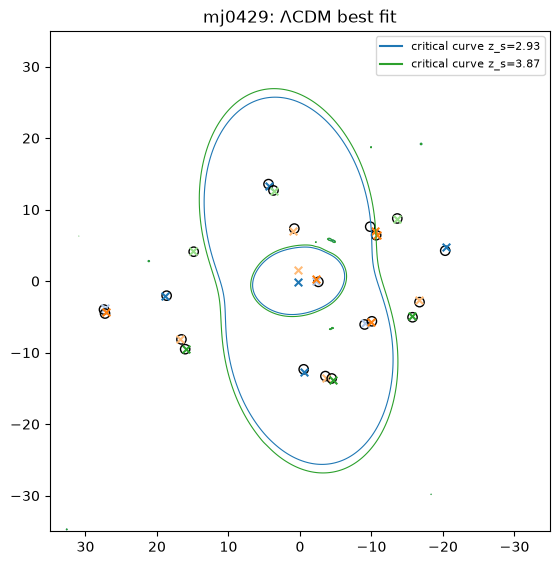

image-plane rms = 0.310 arcsec (expect ~0.27); median |μ| = 4.3; systems with missing images: none


In [5]:
c = calib[MAG_CAP]
m = make_model(MAG_CAP, lens=c["lens"], poi=c["poi"])
P = m.params()
zspec = sorted({s["zs"] for s in systems.values() if s["zerr"] == 0}) or sorted(set(zs_all))
ZCRIT = sorted({zspec[0], zspec[len(zspec) // 2], zspec[-1]})
fig, ax = plt.subplots(figsize=(6.5, 6.5))
g = np.linspace(-LIM, LIM, 501); X, Y = np.meshgrid(g, g)
for zs, col in zip(ZCRIT, ("tab:blue", "tab:green", "tab:red")):
    mu = jax.jit(lambda x, y: m.lensmodel(x, y, zs, P).muinv)(jnp.asarray(X), jnp.asarray(Y))
    ax.contour(X, Y, np.asarray(mu), levels=[0.0], colors=col, linewidths=0.8)
    ax.plot([], [], color=col, label=f"critical curve z_s={zs:.2f}")
offs, mus, missing = [], [], []
for i in range(m.num_poi):
    obs = m.obs_point[i]["tab"]; pred = m.findimg(i + 1)
    o = [np.sqrt(((pred[:, :2] - p[:2]) ** 2).sum(1).min()) if len(pred) else np.inf for p in obs]; offs += o
    mu = np.abs(1 / np.asarray(m.lensmodel(jnp.asarray(obs[:, 0]), jnp.asarray(obs[:, 1]),
                                           float(P["point"][i, 0]), P).muinv)); mus += list(mu)
    if pred.shape[0] < obs.shape[0]:
        missing.append(SIDS[i])
    print(f"system {str(SIDS[i]):>4s} (z={P['point'][i,0]:.3f}): {obs.shape[0]} observed / {pred.shape[0]} predicted, "
          f"offsets {np.round(o, 2)}, |μ| {np.round(mu, 1)}")
    ax.scatter(obs[:, 0], obs[:, 1], marker="o", facecolor="none", edgecolor="k", s=45)
    ax.scatter(pred[:, 0], pred[:, 1], marker="x", color=cmap(i % 20), s=30)
ax.set_xlim(LIM, -LIM); ax.set_ylim(-LIM, LIM); ax.set_aspect("equal"); ax.legend(fontsize=8)
ax.set_title(f"{CLUSTER}: ΛCDM best fit")
plt.show()
rms = np.sqrt(np.mean(np.square(offs)))
print(f"image-plane rms = {rms:.3f} arcsec (expect ~{c['sigma']:.2f}); median |μ| = {np.median(mus):.1f}; "
      f"systems with missing images: {missing or 'none'}")
if rms > 1.0 or missing:
    print("WARNING: the MAP does not reproduce the observed images. Do not run the samplers from it; "
          "try more N_STARTS, a different seed, or a richer model in CLUSTER_MODEL (multipoles, bcg).")

## 3. Stage B: ΛCDM NUTS

The sampled parameters are the free lens parameters and the photometric
redshifts; source positions are marginalised. Each orientation angle is
restricted to one period around the best fit (`gj.angle_bounds`), which
removes the exact θ ↔ θ + 180° copies of the posterior. Chains start near the
best fit, and the dense mass matrix is adapted during warmup.

Healthy output: no or very few divergences, R-hat < 1.01–1.02, ESS of a few
hundred or more. If the median number of gradient evaluations per sample is
2^max_tree_depth − 1, NUTS is running out of tree depth: raise
`max_tree_depth`, or check the parameterization.

In [6]:
def nuts_stage(path, model, theta0, reparam, **over):
    out = load_npz(path)
    if out is not None:
        return out
    pipe = gj.Pipeline(model, reparam=reparam, bounds=gj.angle_bounds(model, theta0))
    pipe.set_map(theta0)
    h = pipe.hmc(checkpoint=path.replace(".npz", ".ckpt"), **dict(NUTS_KW, **over))
    d = gj.diagnostics(h)
    save_npz(path, theta=h["theta"], log_prob=h["log_prob"], diverging=h["diverging"],
             num_steps=h["num_steps"], names=np.array(h["names"]), rhat=d["rhat"], ess=d["ess"],
             time=h["time"])
    return load_npz(path)


def is_source(n):
    return n.startswith("point") and not n.endswith("zs")


def show_diag(res):
    names = list(res["names"]); keep = [k for k, n in enumerate(names) if not is_source(n)]
    th = res["theta"].reshape(-1, len(names))
    print(f"{float(res['time'])/60:.0f} min; divergences {int(res['diverging'].sum())} / {res['diverging'].size}; "
          f"max R-hat {np.nanmax(res['rhat'][keep]):.3f}; min ESS {np.nanmin(res['ess'][keep]):.0f}; "
          f"median {np.median(res['num_steps']):.0f} gradient evaluations per sample")
    print(f"{'parameter':22s} {'mean':>11s} {'std':>10s} {'R-hat':>7s} {'ESS':>7s}")
    for k in keep:
        n = names[k]
        print(f"{label(n):22s} {th[:, k].mean():11.4g} {th[:, k].std():10.3g} "
              f"{res['rhat'][k]:7.3f} {res['ess'][k]:7.0f}")


def lcdm_model(cap):
    c = calib[cap]
    mm = make_model(cap, lens=c["lens"], poi=c["poi"])
    mm.set_source_mode("marginalize")
    return mm


p_nuts = os.path.join(capdir(MAG_CAP), "nuts_lcdm.npz")
nuts_lcdm = load_npz(p_nuts)
if nuts_lcdm is None and RUN_B:
    ml = lcdm_model(MAG_CAP)
    nl = sum(n.startswith("lens") for n in ml.theta_names)
    print(f"{ml.ndim} sampled parameters: {nl} lens, {ml.ndim - nl} photometric redshifts")
    nuts_lcdm = nuts_stage(p_nuts, ml, ml.theta0(), REPARAM)
if nuts_lcdm is not None:
    show_diag(nuts_lcdm)

24 min; divergences 47 / 4000; max R-hat 1.107; min ESS 31; median 127 gradient evaluations per sample
parameter                     mean        std   R-hat     ESS
M_vir [M_sun/h]          4.173e+14   6.28e+13   1.107      31
x_halo                      0.1911      0.082   1.003    1777
y_halo                     0.06509      0.126   1.031     117
e_halo                      0.4314     0.0308   1.104      31
θ_halo                       169.8      0.276   1.040      81
c_halo                       9.124        1.1   1.102      35
σ* [km/s]                    146.3       36.4   1.022     236
r_trun* [arcsec]             17.12       21.4   1.002    1422
η                           0.8738      0.378   1.000    3182
z_s (system 4)               1.755     0.0603   1.021     223
z_s (system 5)               1.643       0.06   1.036     116
z_s (system 6)               1.329     0.0523   1.061      63


## 4. Stage C: validating NUTS with a gradient-free sampler

AIES (the affine-invariant ensemble sampler behind `emcee`) moves its walkers
using the positions of the others, with no gradients. It is far less
efficient than NUTS in high dimensions, but it cannot be misled by a
non-smooth posterior. It samples the *same* posterior: same
parameterization, priors and angle windows. If the marginals agree within
sampling noise, NUTS is trustworthy for this likelihood.

The comparison is only meaningful when both samplers have a usable ESS: with
an ESS of a few, the tolerance is so wide that anything passes.

In [7]:
# p_aies = os.path.join(capdir(MAG_CAP), "aies_lcdm.npz")
# aies = load_npz(p_aies)
# if aies is None and RUN_C:
#     ml = lcdm_model(MAG_CAP); th0 = ml.theta0()
#     pipe = gj.Pipeline(ml, reparam=REPARAM, bounds=gj.angle_bounds(ml, th0))
#     pipe.set_map(th0)
#     e = pipe.ensemble(checkpoint=p_aies.replace(".npz", ".ckpt"), **AIES_KW)
#     save_npz(p_aies, theta=e["theta"], names=np.array(e["names"]))
#     aies = load_npz(p_aies)

# if aies is not None and nuts_lcdm is not None:
#     from numpyro.diagnostics import effective_sample_size
#     a3 = aies["theta"]; a = a3.reshape(-1, a3.shape[-1]); h = nuts_lcdm["theta"].reshape(-1, a.shape[-1])
#     ess_a = np.asarray(effective_sample_size(a3))
#     print(f"{'parameter':22s} {'NUTS mean':>11s} {'AIES mean':>11s} {'NUTS sd':>9s} {'AIES sd':>9s} "
#           f"{'Δmean/sd':>9s} {'sd ratio':>8s}")
#     flag, weak = [], []
#     for k, n in enumerate(aies["names"]):
#         if is_source(n):
#             continue
#         dm = (h[:, k].mean() - a[:, k].mean()) / h[:, k].std()
#         sr = a[:, k].std() / h[:, k].std()
#         tol_m = 3 * np.sqrt(1 / ess_a[k] + 1 / nuts_lcdm["ess"][k])
#         tol_s = 3 * np.sqrt(0.5 / ess_a[k] + 0.5 / nuts_lcdm["ess"][k])
#         if abs(dm) > tol_m or abs(sr - 1) > tol_s:
#             flag.append(label(n))
#         if min(ess_a[k], nuts_lcdm["ess"][k]) < 50:
#             weak.append(label(n))
#         print(f"{label(n):22s} {h[:,k].mean():11.4g} {a[:,k].mean():11.4g} {h[:,k].std():9.3g} "
#               f"{a[:,k].std():9.3g} {dm:9.2f} {sr:8.2f}")
#     print(f"\nAIES ESS {ess_a.min():.0f}-{ess_a.max():.0f}.  "
#           f"Parameters disagreeing beyond 3σ sampling noise: {flag or 'none'}")
#     if weak:
#         print(f"Not a real test (ESS < 50 in one sampler): {weak}")

## 5. Stage D: flat w0waCDM

Ω_m, w0 and wa are sampled jointly with the mass model, with flat priors on:

* Ω_m ∈ [0.05, 1];
* w0 ∈ [−2.5, 0];
* **w0 + wa ∈ [−3, 0)**.

Sampling w0 + wa directly builds the condition w0 + wa < 0 (dark energy
subdominant at early times) into the parameter space, instead of a hard
wall in the posterior. The chains start at the ΛCDM best fit, with
(Ω_m, w0, wa) = (0.3, −1, 0).

In [8]:
def w0wa_stage(cap, run):
    path = os.path.join(capdir(cap), "nuts_w0wa.npz")
    if not run or os.path.exists(path):
        return load_npz(path)
    c = calib[cap]
    mw = make_model(cap, cosmology_free=True, lens=c["lens"], poi=c["poi"])
    mw.set_source_mode("marginalize")
    return nuts_stage(path, mw, mw.theta0(), dict(REPARAM, **COSMO_REPARAM))


nuts_w = w0wa_stage(MAG_CAP, RUN_D)
if nuts_w is not None:
    show_diag(nuts_w)

34 min; divergences 27 / 4000; max R-hat 1.329; min ESS 8; median 255 gradient evaluations per sample
parameter                     mean        std   R-hat     ESS
M_vir [M_sun/h]          3.911e+14   7.32e+13   1.162      16
x_halo                      0.1858     0.0823   1.003    2745
y_halo                     0.04238      0.128   1.084      34
e_halo                      0.4249     0.0316   1.329       8
θ_halo                       169.8       0.28   1.109      22
c_halo                       8.065       1.32   1.190      11
σ* [km/s]                    152.4       39.2   1.037      83
r_trun* [arcsec]             18.04       22.1   1.017     588
η                           0.8639      0.377   1.003    3334
Ω_m                         0.6158      0.258   1.009     526
w0                          -1.121      0.749   1.001    1894
wa                         -0.2565        1.1   1.000    3998
z_s (system 4)               1.811     0.0663   1.036      62
z_s (system 5)               1

## 6. Stage E: cosmology

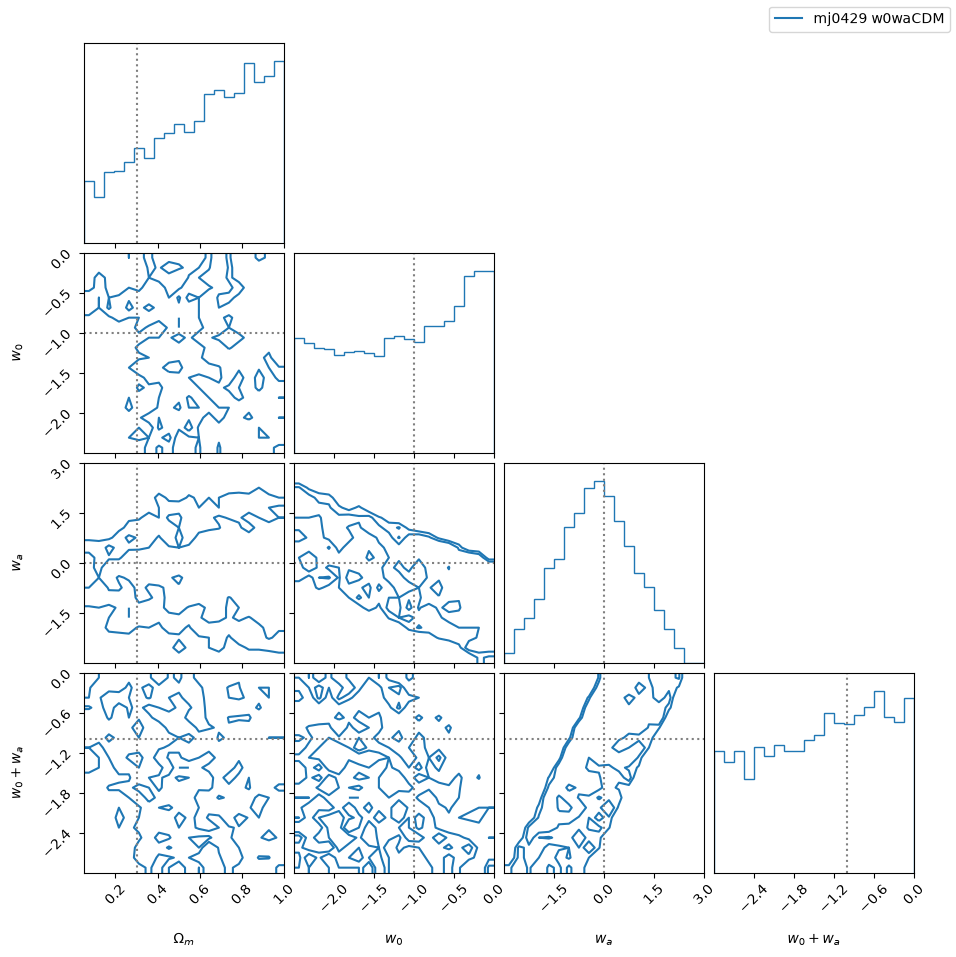

mj0429 w0waCDM
   Ω_m    median  0.658   68%: [ 0.311,  0.897]   95%: [ 0.096,  0.982]
   w0     median -1.047   68%: [-2.047, -0.271]   95%: [-2.438, -0.047]
   wa     median -0.257   68%: [-1.419,  0.891]   95%: [-2.410,  1.841]
   w0+wa  median -1.300   68%: [-2.408, -0.419]   95%: [-2.928, -0.061]

Prior box: Ω_m ∈ [0.05, 1], w0 ∈ [-2.5, 0], w0+wa ∈ [-3, 0).  Intervals that fill the box are prior-dominated, not constraints.


In [9]:
import corner

COS = ("omega", "weos", "wa")
COS_LAB = [r"$\Omega_m$", r"$w_0$", r"$w_a$", r"$w_0+w_a$"]
COS_TXT = ["Ω_m", "w0", "wa", "w0+wa"]
RANGE = [(0.05, 1.0), (-2.5, 0.0), (-3.0, 3.0), (-3.0, 0.0)]


def cosmo_samples(res):
    names = list(res["names"]); th = res["theta"].reshape(-1, len(names))
    om, w0, wa = (th[:, names.index(n)] for n in COS)
    return np.column_stack([om, w0, wa, w0 + wa])


runs = [(f"{CLUSTER} w0waCDM", nuts_w, "tab:blue")]   # add more (label, result, colour) to compare runs
runs = [r for r in runs if r[1] is not None]
if runs:
    fig = None
    for lab, res, col in runs:
        fig = corner.corner(cosmo_samples(res), fig=fig, labels=COS_LAB, range=RANGE, color=col,
                            levels=(0.68, 0.95), plot_datapoints=False, plot_density=False,
                            hist_kwargs=dict(density=True))
    corner.overplot_lines(fig, [0.3, -1.0, 0.0, -1.0], color="0.5", ls=":")
    fig.legend(handles=[plt.Line2D([], [], color=c) for _, _, c in runs], labels=[l for l, _, _ in runs],
               loc="upper right")
    plt.show()
    for lab, res, _ in runs:
        print(lab)
        for cl_, v in zip(COS_TXT, cosmo_samples(res).T):
            q = np.percentile(v, [2.5, 16, 50, 84, 97.5])
            print(f"   {cl_:6s} median {q[2]: .3f}   68%: [{q[1]: .3f}, {q[3]: .3f}]   95%: [{q[0]: .3f}, {q[4]: .3f}]")
    print("\nPrior box: Ω_m ∈ [0.05, 1], w0 ∈ [-2.5, 0], w0+wa ∈ [-3, 0).  Intervals that fill the box "
          "are prior-dominated, not constraints.")

In [10]:
if nuts_w is not None and nuts_lcdm is not None:
    nl, nw = list(nuts_lcdm["names"]), list(nuts_w["names"])
    hl = nuts_lcdm["theta"].reshape(-1, len(nl)); hw = nuts_w["theta"].reshape(-1, len(nw))
    print(f"{'parameter':22s} {'ΛCDM':>24s} {'w0waCDM':>24s}")
    for n in nl:
        if is_source(n):
            continue
        a, b = hl[:, nl.index(n)], hw[:, nw.index(n)]
        print(f"{label(n):22s} {a.mean():13.4g} ± {a.std():8.3g} {b.mean():13.4g} ± {b.std():8.3g}")

parameter                                  ΛCDM                  w0waCDM
M_vir [M_sun/h]            4.173e+14 ± 6.28e+13     3.911e+14 ± 7.32e+13
x_halo                        0.1911 ±    0.082        0.1858 ±   0.0823
y_halo                       0.06509 ±    0.126       0.04238 ±    0.128
e_halo                        0.4314 ±   0.0308        0.4249 ±   0.0316
θ_halo                         169.8 ±    0.276         169.8 ±     0.28
c_halo                         9.124 ±      1.1         8.065 ±     1.32
σ* [km/s]                      146.3 ±     36.4         152.4 ±     39.2
r_trun* [arcsec]               17.12 ±     21.4         18.04 ±     22.1
η                             0.8738 ±    0.378        0.8639 ±    0.377
z_s (system 4)                 1.755 ±   0.0603         1.811 ±   0.0663
z_s (system 5)                 1.643 ±     0.06         1.703 ±    0.067
z_s (system 6)                 1.329 ±   0.0523         1.381 ±   0.0584


### Posterior-predictive check with exact image finding

For random w0waCDM posterior draws, set the sources to their best positions
and solve the lens equation with glafic's exact image finder. Count how many
observed images each draw reproduces, and compute the image-plane rms.

In [11]:
if nuts_w is not None:
    c = calib[MAG_CAP]
    mw = make_model(MAG_CAP, cosmology_free=True, lens=c["lens"], poi=c["poi"])
    mw.set_source_mode("marginalize")     # match the sampled theta (no source positions)
    names = list(nuts_w["names"]); thw = nuts_w["theta"].reshape(-1, len(names))
    rng = np.random.default_rng(1)
    n_ok, rms = 0, []
    nd = 5 if SMOKE_TEST else 20
    for t in thw[rng.choice(len(thw), nd, replace=False)]:
        Pd = mw.best_sources(mw.unflatten(jnp.asarray(t)))
        good, d2 = True, []
        for i in range(mw.num_poi):
            obs = mw.obs_point[i]["tab"]; im = mw.findimg(i + 1, P=Pd)
            good &= im.shape[0] >= obs.shape[0]
            if len(im):
                d2 += [((im[:, :2] - p[:2]) ** 2).sum(1).min() for p in obs]
        n_ok += good; rms.append(np.sqrt(np.mean(d2)))
    print(f"{n_ok}/{nd} draws form at least the observed number of images in every system;  "
          f"image-plane rms = {np.mean(rms):.3f} ± {np.std(rms):.3f} arcsec")

20/20 draws form at least the observed number of images in every system;  image-plane rms = 0.353 ± 0.031 arcsec


## 7. Sampler diagnostics: divergences and near-critical images

Reads the saved chains; nothing is resampled. For every posterior sample, it
computes the magnification of each *observed* image position. An image whose
|μ| reaches the hundreds sits on a critical curve, where the source-plane χ²
is extremely sharp. If the divergences pile up where that image's |μ| blows
up, that image is what limits NUTS.

* **Table:** images whose |μ| exceeds `MU_FLAG` in more than 5% of samples.
  "parity flips" is the fraction of samples in which the image is on the other
  side of the critical curve from the majority.
* **Divergence test:** the divergence rate among the 10% of samples with the
  largest |μ| of the worst image, compared with the rest.
* **Close pairs:** every pair of images in the same system closer than
  `PAIR_SEP`. A pair merging across a critical curve must have opposite
  parities; samples where they share a sign are an unphysical mode. If one
  image of the pair keeps its parity, the suggested `parity` setting for
  `CLUSTER_MODEL` is printed. Images already constrained by `PARITY` are
  checked too: their violation fraction should be 0%.
* **Plots:** M_vir vs e_halo, and e_halo vs the signed 1/μ of the worst image
  (the critical curve is 1/μ = 0), with divergent samples in red; then the
  e_halo trace for each chain.

In [ ]:
MU_FLAG = 100.0                   # |μ| above which an observed image counts as near-critical
PAIR_SEP = 2.0                    # [arcsec] images of one system closer than this are checked as a pair
IMG_IDS = [iid for s in systems.values() for iid in s["ids"]]   # same order as the obs file
CLOSE_PAIRS = [(s["ids"][a], s["ids"][b]) for s in systems.values()
               for a in range(len(s["ids"])) for b in range(a + 1, len(s["ids"]))
               if np.hypot(*np.subtract(s["xy"][a], s["xy"][b])) < PAIR_SEP]


def mu_scan(res, model, batch=500):
    # signed 1/μ at every observed image position for every saved sample -> [n_samples, n_images]
    names = list(res["names"])
    if names != list(model.theta_names):
        raise ValueError("chain parameters do not match the model's")
    th = np.asarray(res["theta"]).reshape(-1, len(names))
    obs = [np.asarray(model.obs_point[i]["tab"]) for i in range(model.num_poi)]

    ls = model.lens_system

    def one(t):
        P = model.unflatten(t)
        # nlp (lens planes in front of the source) must be concrete under vmap: use the precomputed one
        return jnp.concatenate([ls.ray_shoot(jnp.asarray(o[:, 0]), jnp.asarray(o[:, 1]), P["lens"],
                                             P["point"][i, 0], P["cosmo"], nlp=int(model.nlp_point[i])).muinv
                                for i, o in enumerate(obs)])
    f = jax.jit(jax.vmap(one))
    return np.concatenate([np.asarray(f(jnp.asarray(th[k:k + batch]))) for k in range(0, len(th), batch)])


def sampler_diagnostics(title, res, model):
    names = list(res["names"]); nd = len(names)
    th3 = np.asarray(res["theta"]).reshape(-1, *np.shape(res["theta"])[-2:]) if np.ndim(res["theta"]) == 3 \
        else np.asarray(res["theta"])[None]
    th = th3.reshape(-1, nd)
    div = np.asarray(res["diverging"]).reshape(-1).astype(bool)
    t0 = time.time()
    muinv = mu_scan(res, model)
    amu = 1.0 / np.maximum(np.abs(muinv), 1e-12)
    print(f"=== {title}: {len(th)} samples, {div.sum()} divergent; |μ| scan {time.time() - t0:.0f} s")

    # near-critical images
    print(f"{'image':>6s} {'median |μ|':>11s} {'95% |μ|':>9s} {'f(|μ|>' + f'{MU_FLAG:g}' + ')':>11s} "
          f"{'parity flips':>13s} {'median |μ| (div)':>17s}")
    near = []
    for j, iid in enumerate(IMG_IDS):
        frac = np.mean(amu[:, j] > MU_FLAG)
        if frac < 0.05:
            continue
        near.append(iid)
        sgn = np.sign(muinv[:, j]); flips = min(np.mean(sgn > 0), np.mean(sgn < 0))
        mdiv = f"{np.median(amu[div, j]):17.1f}" if div.any() else f"{'-':>17s}"
        print(f"{iid:>6s} {np.median(amu[:, j]):11.1f} {np.percentile(amu[:, j], 95):9.1f} {frac:11.2f} "
              f"{flips:13.3f} {mdiv}")
    if not near:
        print(f"   no image has |μ| > {MU_FLAG:g} in more than 5% of samples")

    # close pairs: a pair merging across a critical curve must have opposite parity
    pos = lambda iid: np.mean(muinv[:, IMG_IDS.index(iid)] > 0)      # fraction with 1/μ > 0
    for a, b in CLOSE_PAIRS:
        same = np.mean(np.sign(muinv[:, IMG_IDS.index(a)]) == np.sign(muinv[:, IMG_IDS.index(b)]))
        msg = f"close pair {a}/{b}: 1/μ > 0 in {pos(a):.0%} / {pos(b):.0%} of samples; same parity in {same:.0%}"
        if same > 0.01:
            stable = [i for i in (a, b) if min(pos(i), 1 - pos(i)) < 0.01]
            if stable:
                sa = 1 if pos(stable[0]) > 0.5 else -1
                other = b if stable[0] == a else a
                msg += (f"  ->  unphysical mode; suggested: parity={{\"{stable[0]}\": {sa:+d}, "
                        f"\"{other}\": {-sa:+d}}}")
            else:
                msg += "  ->  both images flip; fix the signs from the best fit, or drop the pair"
        print(msg)
    for iid, p in PARITY.items():
        bad = np.mean(np.sign(muinv[:, IMG_IDS.index(iid)]) != p)
        print(f"parity constraint {iid} = {p:+d}: violated in {bad:.1%} of samples"
              + ("" if bad == 0 else "  <- the wall is leaking; check the sign convention"))

    # divergences vs the worst image's magnification
    jw = int(np.argmax(np.median(amu, axis=0)))
    if div.any():
        top = amu[:, jw] >= np.percentile(amu[:, jw], 90)
        print(f"divergence rate: {100 * div[top].mean():.1f}% in the 10% of samples with the largest |μ| of "
              f"image {IMG_IDS[jw]}, {100 * div[~top].mean():.1f}% in the rest")

    # chains: per-chain means of the worst-mixing parameters
    keep = [k for k, n in enumerate(names) if not is_source(n)]
    worst = sorted(keep, key=lambda k: -np.nan_to_num(res["rhat"][k]))[:4]
    print("per-chain means (worst R-hat):")
    for k in worst:
        print(f"   {label(names[k]):22s} R-hat {res['rhat'][k]:.3f}: "
              + "  ".join(f"{v:.4g}" for v in th3[:, :, k].mean(axis=1)))

    kM, ke = names.index("lens1_anfw_p2"), names.index("lens1_anfw_p5")
    fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
    ax = axs[0]
    ax.scatter(th[~div, kM], th[~div, ke], s=2, c="0.6", alpha=0.4, label="samples")
    ax.scatter(th[div, kM], th[div, ke], s=12, c="tab:red", label="divergent")
    ax.set_xlabel(label(names[kM])); ax.set_ylabel(label(names[ke])); ax.legend(fontsize=8)
    ax = axs[1]
    ax.scatter(muinv[~div, jw], th[~div, ke], s=2, c="0.6", alpha=0.4)
    ax.scatter(muinv[div, jw], th[div, ke], s=12, c="tab:red")
    ax.axvline(0.0, color="k", lw=0.8, ls=":")
    ax.set_xlabel(f"1/μ of image {IMG_IDS[jw]} (0 = critical curve)"); ax.set_ylabel(label(names[ke]))
    ax = axs[2]
    for ci in range(th3.shape[0]):
        ax.plot(th3[ci, :, ke], lw=0.5, label=f"chain {ci}")
    ax.set_xlabel("sample"); ax.set_ylabel(label(names[ke])); ax.legend(fontsize=7)
    fig.suptitle(f"{CLUSTER}: {title}")
    plt.tight_layout(); plt.show()
    return dict(muinv=muinv, near=near, worst_image=IMG_IDS[jw])


diag = {}
if nuts_lcdm is not None:
    diag["ΛCDM"] = sampler_diagnostics("ΛCDM NUTS", nuts_lcdm, lcdm_model(MAG_CAP))
if nuts_w is not None:
    c = calib[MAG_CAP]
    mw = make_model(MAG_CAP, cosmology_free=True, lens=c["lens"], poi=c["poi"])
    mw.set_source_mode("marginalize")
    diag["w0waCDM"] = sampler_diagnostics("w0waCDM NUTS", nuts_w, mw)

## Notes

* **Running several clusters.** One kernel per cluster: set `GLAFIC_CLUSTER`
  in each batch job (for example `GLAFIC_CLUSTER=mj0429 jupyter nbconvert
  --execute ...`). Results go to separate folders.
* **Interpreting the cosmology.** A single cluster constrains ratios of
  distances, D_ls/D_s, between source redshifts. These ratios depend only
  weakly on (Ω_m, w0, wa) and are degenerate with the mass model. Compare
  the intervals with the prior box: where a posterior fills the box, the data
  have not constrained that parameter. Clusters with many spectroscopic
  systems over a wide redshift range constrain it best.
* **Assumptions worth testing:**
  * the mass-model family, for example adding multipoles or a separate BCG,
    or dropping the shear (`CLUSTER_MODEL`);
  * one common positional error for all images;
  * the photometric-redshift ranges (±4σ, flat).
* **Validation.** Trust stage D only if stage C agrees and its own
  diagnostics are clean.
* **Performance.** NUTS cost is roughly (gradient evaluations per sample) ×
  (time per gradient), and `show_diag` prints the first. On a GPU, more
  chains (`num_chains`) cost little extra, because chains are vectorized.